### Comparison between SteadierCom and experimental results

In [75]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir
import reframed

import libsbml
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

In [76]:
import sys
sys.path.append("../functions/")
import compare_inter_exp_sim

In [77]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

Interactions were found in table (areaThreshold2.mat) from Guillen github repo: https://github.com/Mitchell-SysBio/2021_cellsystems/tree/v1.0.0

This was converted to csv in Matlab (../data/Guillen2021/Guillen_interaction.csv).

In [78]:
exp_interaction = pd.read_csv("../data/Guillen2021/Guillen_interaction.csv",index_col=0)

mutants = ["icd","cysW","panZ","panD","bioH","bioF","bioC"]

exp_interaction = exp_interaction.loc[exp_interaction.index.isin(mutants),exp_interaction.columns.isin(mutants)]
exp_interaction.index = exp_interaction.index.map(lambda x:"mutant_"+x)
exp_interaction.columns = exp_interaction.columns.map(lambda x:"mutant_"+x)
exp_interaction_ser = exp_interaction.stack()
exp_interaction_ser.index.names = ["receiver","donor"]
exp_interaction_ser.name = "experimental" 

**Load steadiercom results**

In [79]:
steadiercom_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_abundance/ecoli_mutants.tsv",sep="\t")

steadiercom_growth = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth/ecoli_mutants.tsv",sep="\t")

steadiercom_growth_abundance = pd.read_csv("../output/Guillen2021/results_steadiercom/results_growth_abundance/ecoli_mutants.tsv",sep="\t")

**Load smetana results**

In [80]:
smetana = pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")

**Load steadycom results**

In [81]:
steadycom_fixed_abundance = pd.read_csv("../output/Guillen2021/steadycom/cross_feeding_fixed_abundance.tsv",sep="\t")
steadycom = pd.read_csv("../output/Guillen2021/steadycom/cross_feeding.tsv",sep="\t")

**Process data**

In [82]:
steadiercom_dict = {
    "SteadierCom - Fixed growth":steadiercom_growth,
    "SteadierCom - Fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - Fixed abundance":steadiercom_abundance
}
steadiercom_dict_inter = {}

for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.donor!="environment") & (simulated.receiver!="environment")].copy()
    steadiercom_dict_inter[name]=simulated


steadiercom_dict_rec = {}
for name,simulated in steadiercom_dict.items():
    simulated = simulated[(simulated.receiver!="environment")].copy()
    steadiercom_dict_rec[name]=simulated


steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed abundance":steadycom_fixed_abundance
}
steadycom_dict_inter = {}

for name,simulated in steadycom_dict.items():
    simulated = simulated.dropna().copy()
    steadycom_dict_inter[name]=simulated


steadycom_dict_rec = {}
for name,simulated in steadycom_dict.items():
    simulated = simulated.fillna("environment")
    simulated = simulated[(simulated.receiver!="environment")].copy()   
    steadycom_dict_rec[name]=simulated


## Cooperation - SteadierCom

#### SteadierCom - scatterplot - frequency counts

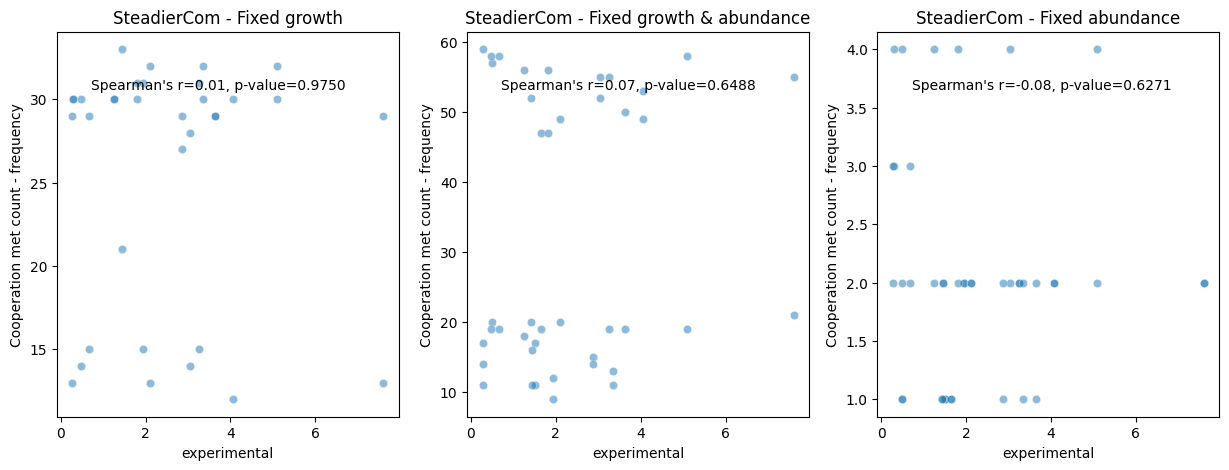

In [110]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_inter,
                                  exp_interaction_ser,
                                  coop_or_comp="coop",
                                  metric="frequency",
                                  sim_thresh =0.01,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

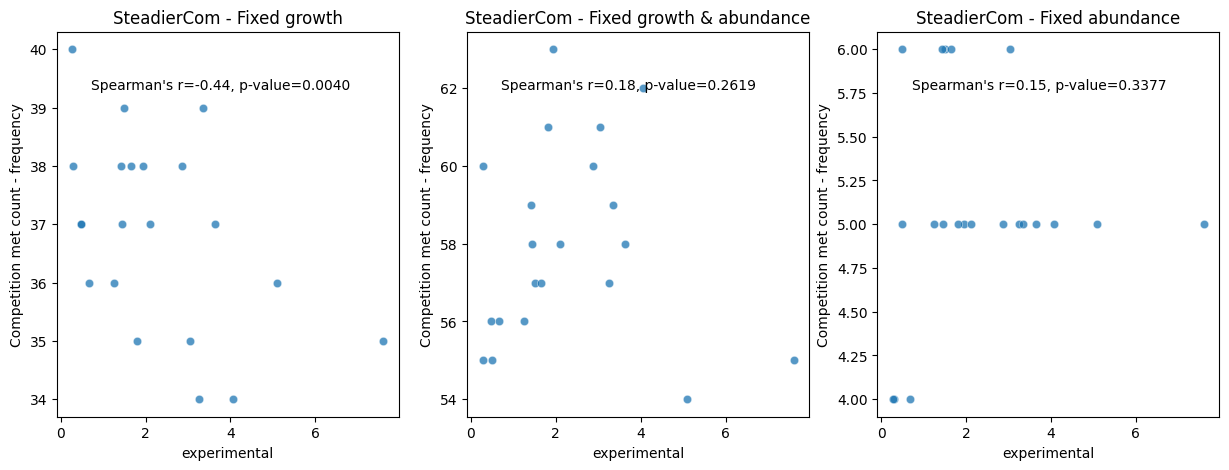

In [122]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_rec,
                                  exp_interaction_ser,
                                  coop_or_comp="comp",
                                  metric="frequency",
                                  sim_thresh =0.01,
                                  count_or_sum="count")

fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadierCom - scatterplot - rate sum

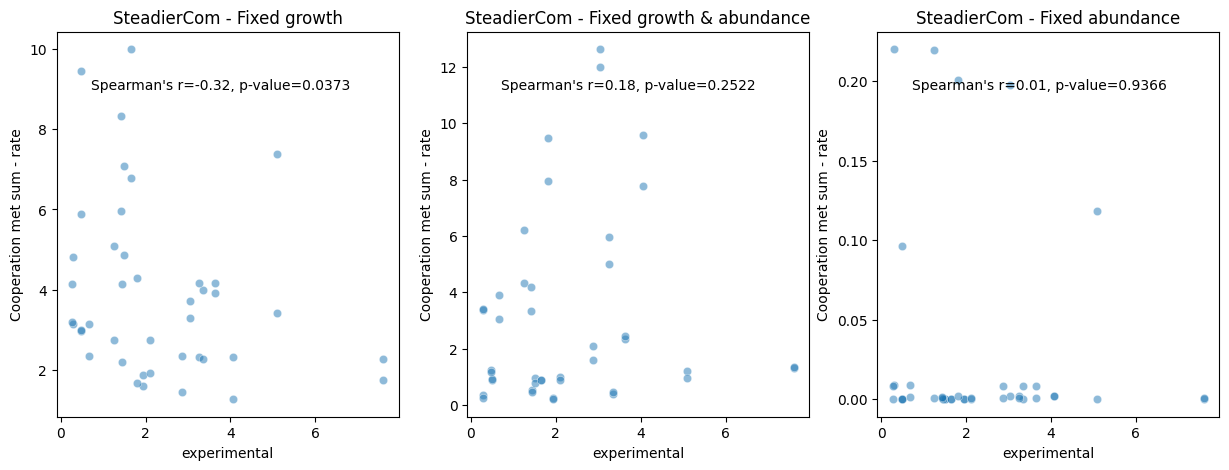

In [115]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_inter,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="coop",
                                                                       metric="rate",
                                                                       sim_thresh =False,
                                                                       count_or_sum="sum")
fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

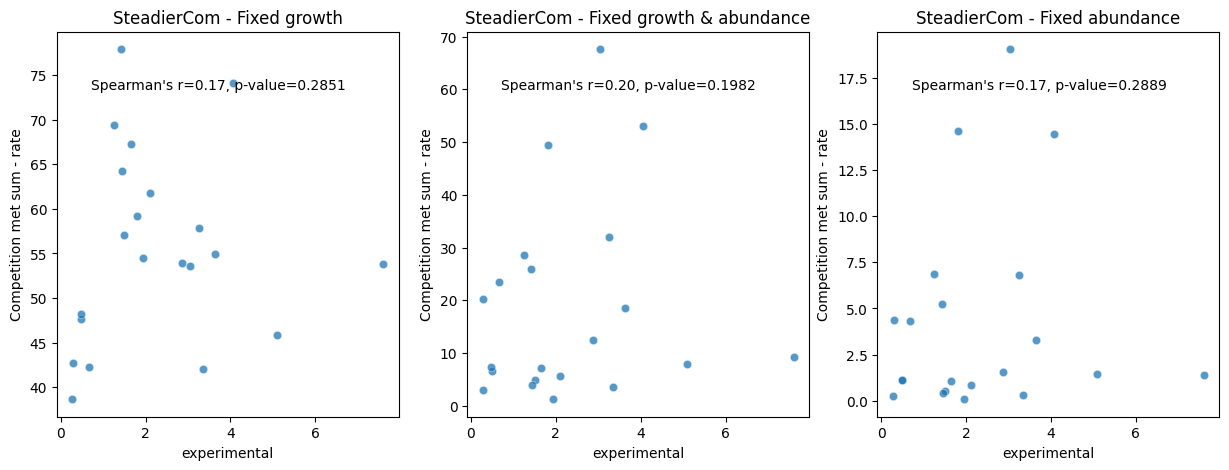

In [124]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_rec,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="comp",
                                                                       metric="rate",
                                                                       sim_thresh =False,
                                                                       count_or_sum="sum")
fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

#### SteadierCom - scatterplot - rate count

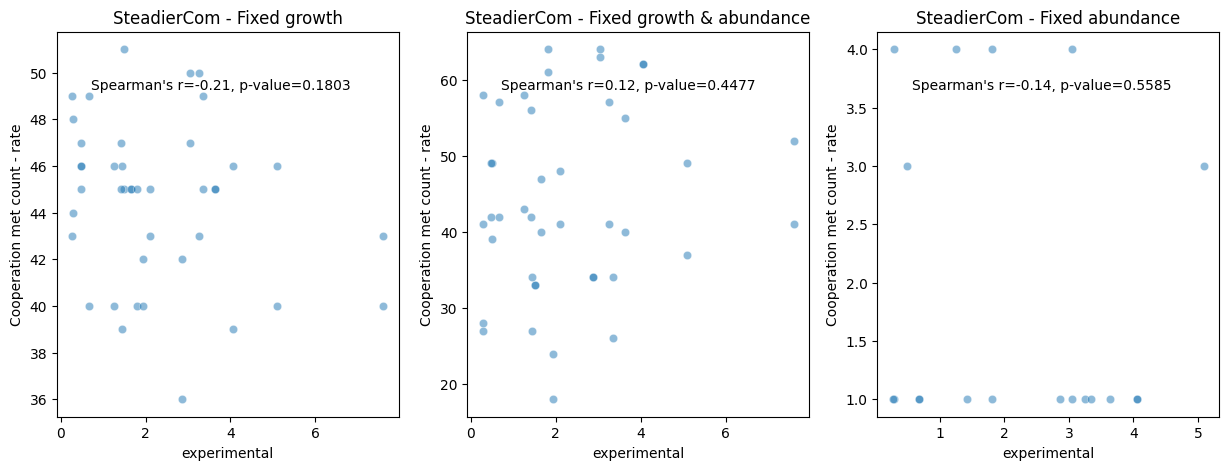

In [116]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_inter,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="coop",
                                                                       metric="rate",
                                                                       sim_thresh =1e-3,
                                                                       count_or_sum="count")
fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

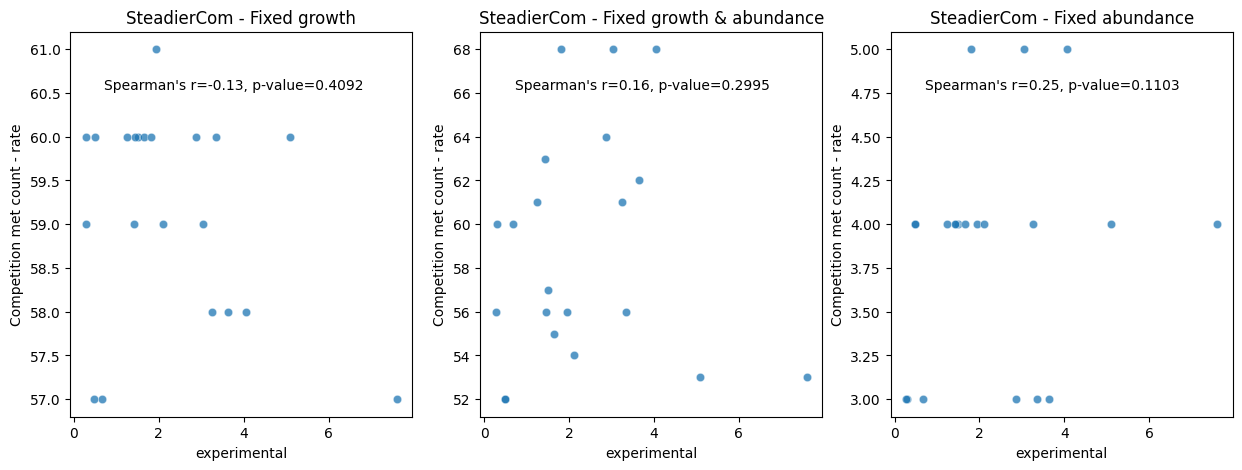

In [125]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadiercom_dict_rec,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="comp",
                                                                       metric="rate",
                                                                       sim_thresh =1e-3,
                                                                       count_or_sum="count")
fig, axs = plt.subplots(1,3,figsize=(15,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

### Cooperation SteadyCom

#### SteadyCom - scatterplot - cooperation (sum)

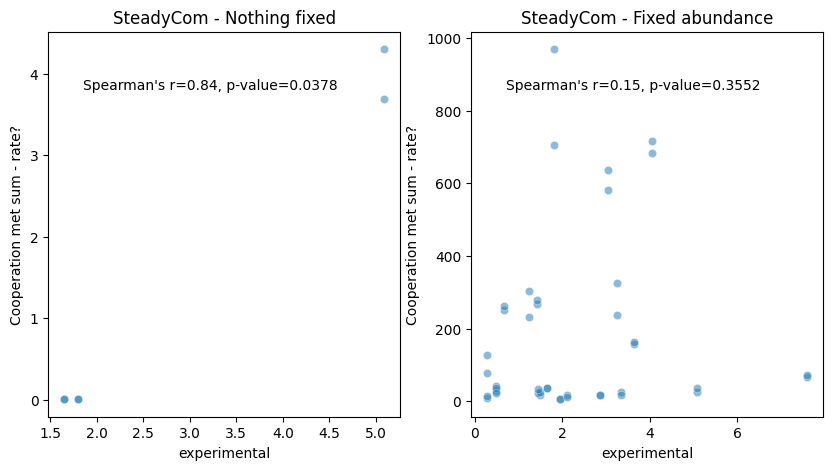

In [120]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadycom_dict_inter,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="coop",
                                                                       metric="rate?",
                                                                       sim_thresh =False,
                                                                       count_or_sum="sum")
fig, axs = plt.subplots(1,2,figsize=(10,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

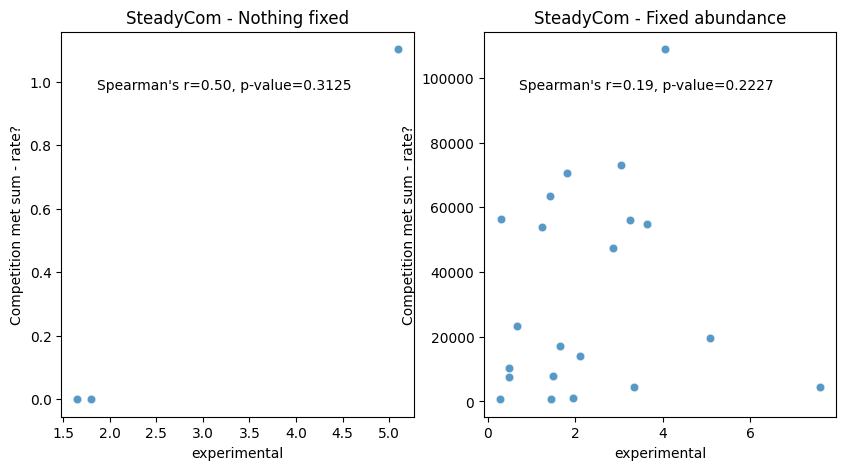

In [126]:
data_dict,label_dict = compare_inter_exp_sim.coop_comp_exp_communities(steadycom_dict_rec,
                                                                       exp_interaction_ser,
                                                                       coop_or_comp="comp",
                                                                       metric="rate?",
                                                                       sim_thresh =False,
                                                                       count_or_sum="sum")
fig, axs = plt.subplots(1,2,figsize=(10,5))

i = 0
for name,exp_sim_combined in data_dict.items():
    compare_inter_exp_sim.plot_coop_comp(exp_sim_combined=exp_sim_combined,
                                                   name=name,
                                                   ax=axs[i],
                                                   label_dict=label_dict)
    i+=1

### Competition and cooperation - combined

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor & exp_sim_combined.dropna()
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:216: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


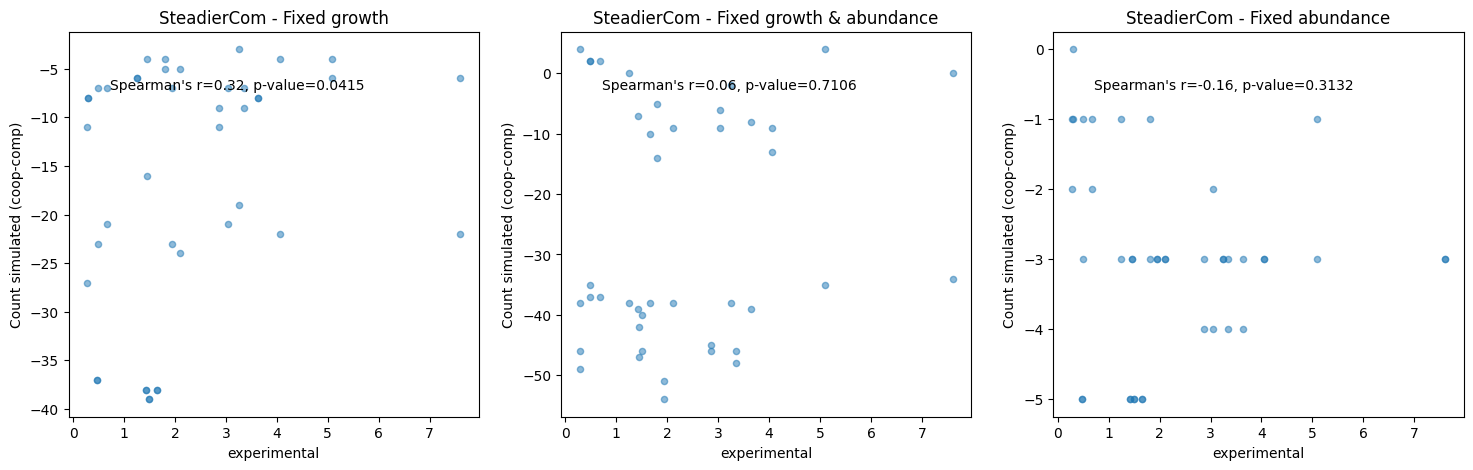

In [153]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="frequency",
                                              count_or_sum="count",
                                              sim_thresh=0.01)

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor & exp_sim_combined.dropna()
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:216: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


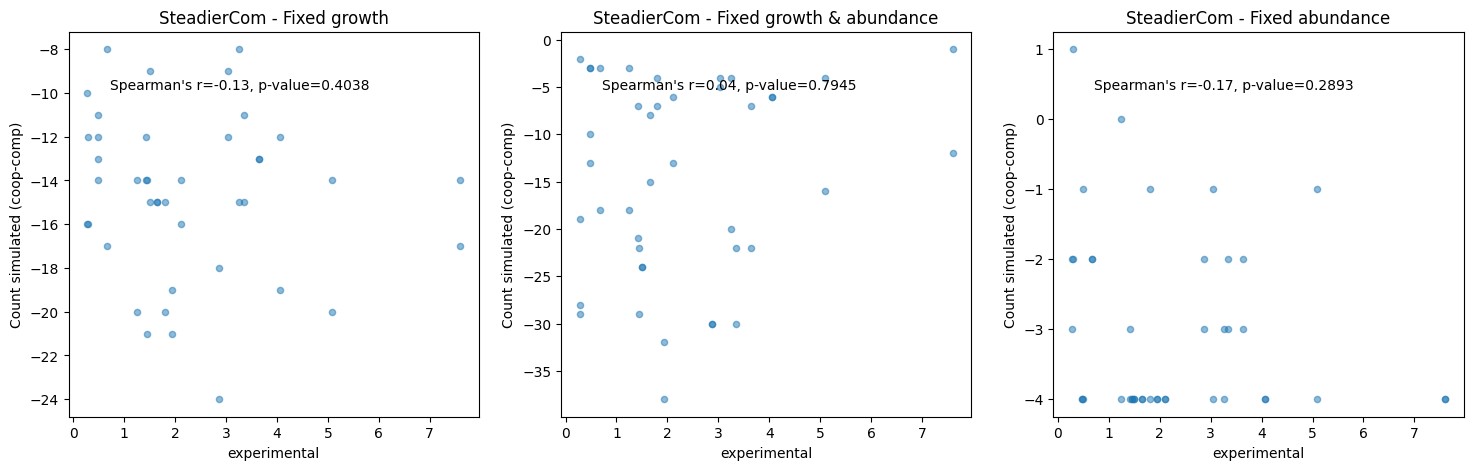

In [163]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="rate",
                                              count_or_sum="count",
                                              sim_thresh=1e-3)

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor & exp_sim_combined.dropna()
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:216: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


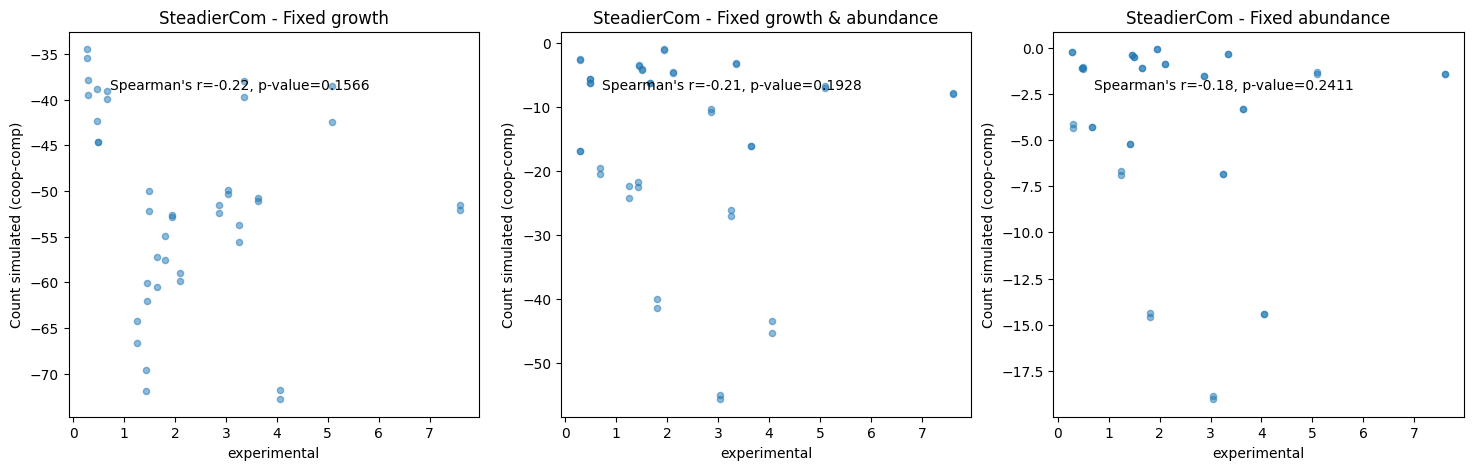

In [157]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadiercom_dict_rec,
                                              simulated_dict_inter=steadiercom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="rate",
                                              count_or_sum="sum",
                                              sim_thresh=False)

[INFO] 'plot_coop_comp_combined' filters data: receiver!=donor & exp_sim_combined.dropna()
/Users/idunmariaburgos/SteadierCom/case_studies/notebooks/../functions/compare_inter_exp_sim.py:216: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations


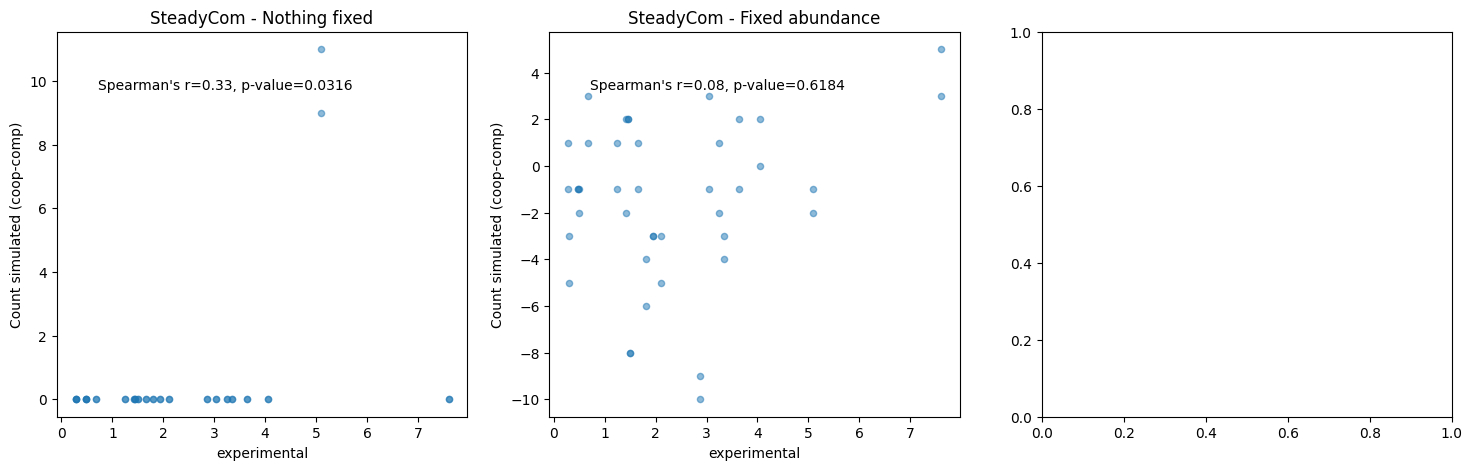

In [162]:
fig,axs = compare_inter_exp_sim.plot_coop_comp_combined(simulated_dict_rec=steadycom_dict_rec,
                                              simulated_dict_inter=steadycom_dict_inter,
                                              exp_ser=exp_interaction_ser,
                                              metric="rate?",
                                              count_or_sum="count",
                                              sim_thresh=1e-2)